# False Positive Analysis
## Objective
- find out WHY the detector falsely flags human-written text as AI-generated
- test the trained model on outside/new human-written text samples (not from our training data) to find out WHY it falsely flags genuine human writing as AI-generated

1. Filter rows where author=human and predicted=ai (false positives)
2. Compare these false positives against correctly-classified human text (author=human, predicted=human) — are they shorter, more formal, less "bursty" in sentence length, from a specific domain?
3. Pull 3-5 actual example sentences from the false positives to quote as evidence.
4. Create a simple bar chart or table showing the difference in features (Use teammate 2's (objective 2 extract_features() from feature engineering, use that; otherwise just use word count/sentence variance).
5. Summarize the pattern in 2-3 sentences I can put directly into my report section.
6. Load our trained model and vectorizer with pickle

- already has results/test_predictions.csv from your training run, just load that CSV and filter

**First analyse test_prediction.csv why our model testing flagging human text as AI then use the data/processed/Detect_hum benchmark and paste those text into our model and test how our model prediciting and compare with other models prediction(Detect_hum/results.csv)**

In [4]:

!pip install pandas


  Using cached tzdata-2026.3-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   -------------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

df = pd.read_csv("../results/test_predictions.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Shape: (13628, 7)
Columns: ['text', 'author', 'gen_source', 'domain', 'source_dataset', 'split', 'predicted']


,text,author,gen_source,domain,source_dataset,split,predicted
0,A collection of characters with a same design ...,ai,ai-generated and ai-refined and human-written,unknown,txd_22,test,ai
1,Paddy farming refers to the specialized cultiv...,ai,chatgpt,unknown,txd_22,test,ai
2,Fishes are aquatic vertebrates characterized b...,ai,perplexity,unknown,txd_22,test,ai
3,Developing countries face a myriad of challeng...,ai,blackboxai,unknown,txd_22,test,ai
4,The balance of payments is a comprehensive fin...,ai,poe,unknown,txd_22,test,ai


In [4]:
# False Positives:
# Actual = human
# Predicted = ai

false_positives = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "ai")
].copy()

# Correctly classified human texts
correct_human = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "human")
].copy()

print("False Positive count:", len(false_positives))
print("Correct Human count:", len(correct_human))

False Positive count: 734
Correct Human count: 702


In [5]:
print("===== FALSE POSITIVE HUMAN TEXTS =====")

for i, text in enumerate(false_positives["text"].head(5), 1):
    print(f"\n--- Example {i} ---")
    print(text)
    

===== FALSE POSITIVE HUMAN TEXTS =====

--- Example 1 ---
used for creating realistic face animations of virtual actors for applications in computer animation, film, and video games. Creation of convincing facial animation is a challenging task due to the highly nonrigid nature of the face and the complexity of detecting and tracking the facial landmarks accurately and efficiently in uncontrolled environments. It involves facial deformation and fine-grained details. In addition, the uncanny valley effect [1] indicates that people are extremely capable of identifying subtle artifacts in facial appearance. Hence, animators need to make a tremendous amount of effort to localize high quality facial landmarks. To reduce the amount of manual labor, an ideal face capture solution should automatically provide the facial shape (landmarks) with high performance given reasonable quality input videos.

--- Example 2 ---
Climatic change is considered likely to increase runoff in the higher latitude

In [6]:
false_positives.to_csv(
    "../results/false_positives.csv",
    index=False
)

print("False positives saved successfully.")

False positives saved successfully.


In [7]:
print(df.columns.tolist())

['text', 'author', 'gen_source', 'domain', 'source_dataset', 'split', 'predicted']


In [8]:
# Human text incorrectly predicted as AI
false_positives = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "ai")
].copy()

# Human text correctly predicted as Human
correct_human = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "human")
].copy()

print("False Positive count:", len(false_positives))
print("Correct Human count:", len(correct_human))

False Positive count: 734
Correct Human count: 702


In [10]:
!pip install scikit-learn


     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.0 kB ? eta -:--:--
     ------------------------------- ------ 51.2/61.0 kB 525.1 kB/s eta 0:00:01
     -------------------------------------- 61.0/61.0 kB 465.2 kB/s eta 0:00:00
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached narwhals-2.24.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/8.3 MB 1.6 MB/s eta 0:00:06
   ---------------------------------------- 0.1/8.3 MB 2.0 MB/s eta 0:00:05
   - -------------------------------------- 0.2/8.3 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.3/8.3 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.3 MB 1.6 MB/s eta 0:00:05
   -- ------------------------------------- 0.4/8


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
print("Author values:")
print(df["author"].value_counts())

print("\nPredicted values:")
print(df["predicted"].value_counts())

Author values:
author
ai       12192
human     1436
Name: count, dtype: int64

Predicted values:
predicted
ai       12843
human      785
Name: count, dtype: int64


In [12]:
false_positives = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "ai")
].copy()

print("False Positive count:", len(false_positives))


False Positive count: 734


In [13]:
correct_human = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "human")
].copy()

print("Correct Human count:", len(correct_human))

Correct Human count: 702


In [14]:
print("False Positives by domain:")
print(false_positives["domain"].value_counts())

print("\nCorrect Human by domain:")
print(correct_human["domain"].value_counts())

False Positives by domain:
domain
unknown                                         509
Genetics and Genomics                            34
Computer Science and Artificial Intelligence     30
Social Sciences and Humanities                   29
Climate Science and Environmental Studies        28
Astrophysics and Astronomy                       26
Mathematics and Statistics                       16
Neuroscience and Psychology                      16
Medical Research and Healthcare                  15
Natural Language Processing                      14
Materials science and engineering                14
Materials Science and Engineering                 3
Name: count, dtype: int64

Correct Human by domain:
domain
unknown                                         124
Astrophysics and Astronomy                       87
Computer Science and Artificial Intelligence     80
Social Sciences and Humanities                   58
Genetics and Genomics                            55
Natural Language Proces

In [16]:
false_positives["word_count"] = (
    false_positives["text"]
    .fillna("")
    .str.split()
    .str.len()
)

correct_human["word_count"] = (
    correct_human["text"]
    .fillna("")
    .str.split()
    .str.len()
)

In [17]:
print("False Positive average word count:",
      false_positives["word_count"].mean())

print("Correct Human average word count:",
      correct_human["word_count"].mean())

False Positive average word count: 262.6907356948229
Correct Human average word count: 193.64102564102564


In [18]:
print("False Positive median:",
      false_positives["word_count"].median())

print("Correct Human median:",
      correct_human["word_count"].median())

False Positive median: 264.0
Correct Human median: 192.0


In [19]:
import re
import numpy as np

def sentence_features(text):
    text = str(text)

    sentences = re.split(r'[.!?]+', text)

    sentences = [
        s.strip()
        for s in sentences
        if s.strip()
    ]

    if len(sentences) == 0:
        return pd.Series({
            "sentence_count": 0,
            "avg_sentence_length": 0,
            "sentence_length_variance": 0
        })

    lengths = [
        len(sentence.split())
        for sentence in sentences
    ]

    return pd.Series({
        "sentence_count": len(sentences),
        "avg_sentence_length": np.mean(lengths),
        "sentence_length_variance": np.var(lengths)
    })

In [20]:
fp_sentence_features = false_positives["text"].apply(sentence_features)

ch_sentence_features = correct_human["text"].apply(sentence_features)

In [21]:
false_positives = pd.concat(
    [false_positives, fp_sentence_features],
    axis=1
)

correct_human = pd.concat(
    [correct_human, ch_sentence_features],
    axis=1
)

In [22]:
comparison = pd.DataFrame({
    "Feature": [
        "Word Count",
        "Sentence Count",
        "Average Sentence Length",
        "Sentence Length Variance"
    ],
    "False Positive (Human → AI)": [
        false_positives["word_count"].mean(),
        false_positives["sentence_count"].mean(),
        false_positives["avg_sentence_length"].mean(),
        false_positives["sentence_length_variance"].mean()
    ],
    "Correct Human (Human → Human)": [
        correct_human["word_count"].mean(),
        correct_human["sentence_count"].mean(),
        correct_human["avg_sentence_length"].mean(),
        correct_human["sentence_length_variance"].mean()
    ]
})

comparison

,Feature,False Positive (Human → AI),Correct Human (Human → Human)
0,Word Count,262.690736,193.641026
1,Sentence Count,11.107629,9.712251
2,Average Sentence Length,24.395202,20.689876
3,Sentence Length Variance,115.426021,111.518353


In [23]:
print(false_positives[["text", "domain"]].head(10))

                                                  text  \
13   used for creating realistic face animations of...   
15   Climatic change is considered likely to increa...   
47   The vision of a more personalized, consumer-or...   
94   Maxwell's Equations are four basic equations t...   
114  Classic security and the human security are tw...   
126  Movements are performed by plants to achieve t...   
131  Cyber-Physical system (CPS) is considered as o...   
139  MicroRNAs (miRNAs) are small non-coding RNAs (...   
182  Video editor AviSynth Video editing software i...   
183  Observations from a network of specially equip...   

                                           domain  
13   Computer Science and Artificial Intelligence  
15      Climate Science and Environmental Studies  
47                Medical Research and Healthcare  
94                                        unknown  
114                                       unknown  
126                                       unknown

In [24]:
print(correct_human[["text", "domain"]].head(10))

                                                  text  \
41   Officials confirmed on Tuesday that genomic re...   
50   The TRADITIONAL solution to the slow-wave stru...   
59   The 13.7 meter radio telescope (Urpo 1975) at ...   
63   The current observational sample of extrasolar...   
69   idk why supply chain disruptions keeps coming ...   
75   Kepler is a discovery-class mission designed t...   
85   Local authorities are responding to reports th...   
92   COMPARING genomic organization between differe...   
103  Gender disparities in the allocation of housew...   
118  Different methods and algorithms have been pro...   

                                domain  
41                                news  
50   Materials science and engineering  
59          Astrophysics and Astronomy  
63          Astrophysics and Astronomy  
69                              social  
75          Astrophysics and Astronomy  
85                                news  
92               Genetics and Gen

In [25]:
examples = false_positives[
    ["text", "domain", "source_dataset"]
].sample(5, random_state=42)

examples

,text,domain,source_dataset
10209,"Sampling is the act, process, or technique of ...",unknown,txd_22
656,The growth and the spread of the Ottoman Empir...,unknown,txd_22
5011,"In power systems, the term faults is used to d...",unknown,txd_22
3488,Style and performance are two concepts that ha...,Social Sciences and Humanities,ai_h
3396,"Sociology is the study of society, social inst...",unknown,txd_22


In [26]:
pd.set_option("display.max_colwidth", None)

examples

,text,domain,source_dataset
10209,"Sampling is the act, process, or technique of selecting a suitable sample, or a representative part of a population for the purpose of determining parameters or characteristics of the whole population. As researching an entire population is rarely feasible, almost all social research is conducted on a sample rather than the entire population, and researchers must sample only a portion of the population to generate results capable of being generalized from the sample to the population. The selected group is referred to as a sample, and the entire group from which the sample is drawn is the population. Sampling plays a key role in the field of statistics and research by providing analysts an opportunity estimate population parameters, testing hypothesis, and making prediction without analyzing all members of the population from which sample has been created. In order for sampling to be successful and produce accurate results, the sample must be representative of the population, or those characteristics that describe the population, must be proportional to the sample. There are two major types of sampling: Probability Sampling A sample chosen from a larger population by using a chance process or a random number generator in which each member of the population has a known probability of being chosen and non-probability sampling in which no probability is attached to members of the population as a basis for selecting them. Some of the probability sampling techniques are, simple random sampling, stratified sampling, cluster sampling and systematic sampling, and each of these has their own methodologies and applications. Non-probability techniques are convenience, quota and purposive. Sampling is closely related to ideas like sampling distribution, standard error, and confidence intervals which are used to quantify the uncertainty and variability of estimates coming from it. The sample size is an essential factor in such case as well; the larger the sample, the more accurate the estimates, though such collection may require more resources. Inferior sampling may result in bias, which decreases the validity of inference. Sampling is applicable to a variety of fields such as opinion polling, medical research, business market and quality control. At the end of the day, sampling allows investigators and decision makers to study diverse populations to quickly draw inferences that may be applicable to broader groups.",unknown,txd_22
656,"The growth and the spread of the Ottoman Empire started from the late 13th century, where the former began its expansion in the hands of the its first leader, Osman I and his successors. At first, the Ottomans were just one of the many Turkish states in Anatolia, but they survived and took shape into a dynasty because of the labour organization and unique military tactics and power. An elite infantry corps, the Janissaries, created by the Dev?irme (the forced recruitment of Christian children), was the loyal and disciplined base. Through the use of gunpowder (which was invented in the east specifically as a siege weapon) and effectively ending the siege in the Balkans, the Ottomans captured both the Balkans' strategically-most important city, Byzantine Thessaloniki, in 1387, and the Byzantine capital, Constantinople in 1453. It was a cataclysmic event, the fall of Constantinople in 1453 at the hands of Mehmed II, which resulted in the extinction of the Byzantine Empire and made Istanbul a vibrant cultural and economic center. The victory gave the Ottomans control of trade routes between Europe and Asia. The Ottomans rose to dominance under Suleiman the Magnificent in the 16th century when they conquered Baghdad, Rhodes and portions of Hungary, including Belgrade, and made the empire a global powerhouse that spanned three continents — Europe, Asia and Africa. Ottoman rule integrated a highly centralized system with moderate provincial autonomy, much to the benefit of both T

In [27]:
print("False Positives by source dataset:")
print(false_positives["source_dataset"].value_counts())

print("\nCorrect Human by source dataset:")
print(correct_human["source_dataset"].value_counts())

False Positives by source dataset:
source_dataset
txd_22    509
ai_h      225
Name: count, dtype: int64

Correct Human by source dataset:
source_dataset
ai_h      470
txd_22    124
gpt_t2    108
Name: count, dtype: int64


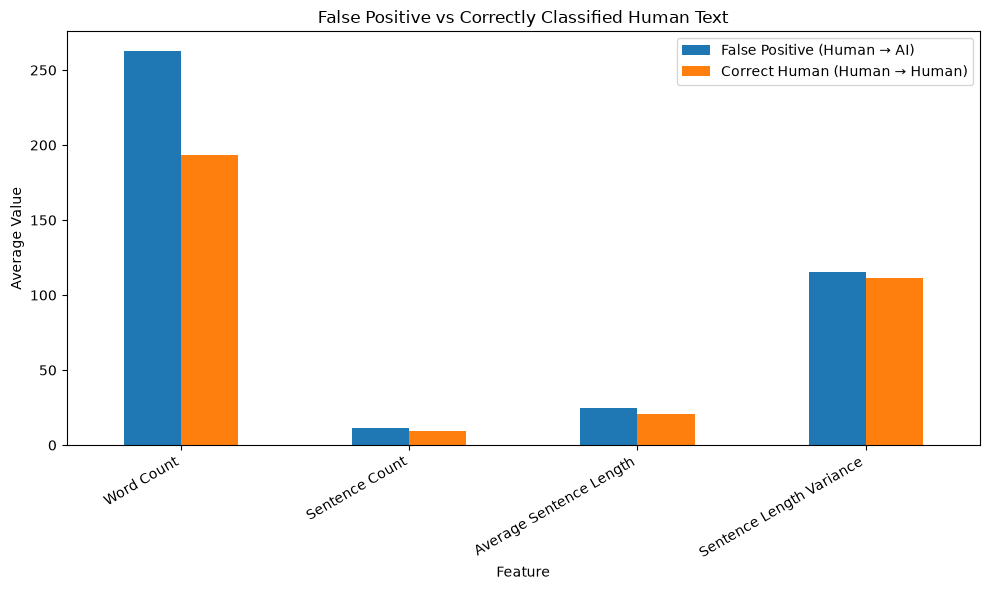

In [30]:
import matplotlib.pyplot as plt

comparison.plot(
    x="Feature",
    y=[
        "False Positive (Human → AI)",
        "Correct Human (Human → Human)"
    ],
    kind="bar",
    figsize=(10, 6)
)

plt.title("False Positive vs Correctly Classified Human Text")
plt.ylabel("Average Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [29]:
import sys
!{sys.executable} -m pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 163.8 kB/s eta 0:00:01
     ------------------- ------------------ 41.0/80.3 kB 178.6 kB/s eta 0:00:01
     --------------------------------- ---- 71.7/80.3 kB 262.6 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 263.2 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/121.0 kB ? eta -:--:--
     ------------------- ------------------- 61.4/121.0 kB 1.7 MB/s eta 0:00:01
     ----------------------------- --------- 92.2/121.0 kB 1.1 MB/s eta 0:00:01
     ----------------------------------- -- 112.6/121.0 kB 1.1 MB/s eta 0:00:01
     --------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import pickle

with open("models/baseline_model.pkl", "rb") as f:
    model = pickle.load(f)

with open("models/tfidf_vectorizer.pkl", "rb") as f:
    vectorizer = pickle.load(f)

print("Model:", type(model))
print("Vectorizer:", type(vectorizer))

FileNotFoundError: [Errno 2] No such file or directory: 'models/baseline_model.pkl'

In [32]:
new_text = """
I went to the library yesterday to complete my assignment.
The place was quiet, so I was able to concentrate on my work.
After finishing the assignment, I went home in the evening.
"""

X_new = vectorizer.transform([new_text])

prediction = model.predict(X_new)

print("Prediction:", prediction[0])

NameError: name 'vectorizer' is not defined